# Breast Cancer Detection and Data Analysis Using Machine Learning
**AIM111 – Introduction to Data Science | Final Project | Dexter Brokeshoulder**

Supporting analytical notebook for the Exercise 32 proposal. Investigate diagnostic measurements, compare malignant and benign observations, and evaluate a linear Support Vector Machine (SVM) on held-out data. This is an educational demonstration, not a clinical diagnostic tool.

**Workflow:** ingest → validate → explore → split → fit → score → predict → evaluate → verify.

## 1. Setup and data ingestion
Place the supplied CSV next to this notebook (or upload it into Colab). The built-in equivalent dataset is a fallback if no CSV is present. Dependencies: `pandas numpy matplotlib seaborn scikit-learn`; optional notebook controls: `ipywidgets`. Install missing packages with `%pip install pandas numpy matplotlib seaborn scikit-learn ipywidgets` in a notebook cell. Restart the kernel and Run All.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score)
from sklearn.base import clone
import sklearn
sns.set_theme(style='whitegrid')
LABELS = {0: 'Malignant', 1: 'Benign'}
ORDER = ['Malignant', 'Benign']
PALETTE = {'Malignant': '#b33c45', 'Benign': '#297b91'}
reference = load_breast_cancer()
features = list(reference.feature_names)
paths = [Path('breast_cancer_dataset(1).csv'), Path('breast_cancer_dataset.csv')]
source = next((p for p in paths if p.is_file()), None)
if source is not None:
    df = pd.read_csv(source)
else:
    df = pd.DataFrame(reference.data, columns=features).assign(target=reference.target)
print('Source:', source if source else 'scikit-learn built-in dataset')
print('Versions:', 'pandas', pd.__version__, '| scikit-learn', sklearn.__version__)
display(df.head())

Source: breast_cancer_dataset.csv
Versions: pandas 2.2.3 | scikit-learn 1.8.0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 2. Dataset overview and quality checks
The Wisconsin Diagnostic dataset contains 569 observations and 30 numeric features derived from digitized fine-needle aspirate images. Ten measurement families (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry and fractal dimension) are represented by mean, standard error and worst values. Target 0 is malignant; 1 is benign. The unrelated recurrence dataset description in the original notebook has been removed.

Validate the supplied data before fitting. No silent row removal or imputation is performed; unexpected quality failures stop execution.

,dtype,missing,min,max
mean radius,float64,0,6.981000,28.11000
mean texture,float64,0,9.710000,39.28000
mean perimeter,float64,0,43.790000,188.50000
mean area,float64,0,143.500000,2501.00000
mean smoothness,float64,0,0.052630,0.16340
mean compactness,float64,0,0.019380,0.34540
mean concavity,float64,0,0.000000,0.42680
mean concave points,float64,0,0.000000,0.20120
mean symmetry,float64,0,0.106000,0.30400
mean fractal dimension,float64,0,0.049960,0.09744


Duplicate rows: 0
Schema, values and target mapping verified against reference; no cleaning required.


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


,Count,Percent
Diagnosis,,
Malignant,212,37.26
Benign,357,62.74


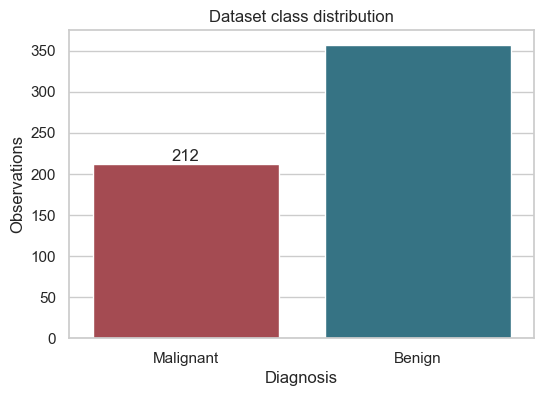

In [2]:
assert set(df.columns) == set(features + ['target']), 'Unexpected feature schema'
assert df.shape == (569, 31), 'Unexpected dataset dimensions'
assert all(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns)
assert set(df.target.unique()) == {0, 1}, 'Unexpected labels'
quality = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                        'min': df.min(), 'max': df.max()})
display(quality)
print('Duplicate rows:', df.duplicated().sum())
assert not df.isna().any().any() and np.isfinite(df.to_numpy()).all()
assert not df.duplicated().any(), 'Review duplicates before splitting'
# Compare values and labels with the reference dataset, including row order.
assert np.allclose(df[features].to_numpy(), reference.data)
assert np.array_equal(df.target.to_numpy(), reference.target)
print('Schema, values and target mapping verified against reference; no cleaning required.')
eda = df.assign(Diagnosis=df.target.map(LABELS))
display(df[features].describe().T)
counts = eda.Diagnosis.value_counts().reindex(ORDER)
display(pd.DataFrame({'Count': counts, 'Percent': counts / len(df) * 100}).round(2))
fig, ax = plt.subplots(figsize=(6,4))
sns.countplot(data=eda, x='Diagnosis', hue='Diagnosis', order=ORDER, palette=PALETTE, legend=False, ax=ax)
ax.bar_label(ax.containers[0]); ax.set(title='Dataset class distribution', ylabel='Observations')
plt.show()

## 3. Feature exploration
Compare class-specific summary statistics, visualize Pearson correlations, and inspect selected measurements. Correlation is descriptive and is not evidence of causation. Because benign is coded 1, negative target correlations indicate higher feature values tend to occur in malignant observations. These exploratory views are not used to select or tune model features; the SVM uses all 30.

mean radius                mean texture                \
                 mean  median    std         mean median    std   
Diagnosis                                                         
Benign         12.147  12.200  1.781       17.915  17.39  3.995   
Malignant      17.463  17.325  3.204       21.605  21.46  3.779   

          mean perimeter                 mean area                  \
                    mean  median     std      mean median      std   
Diagnosis                                                            
Benign            78.075   78.18  11.807   462.790  458.4  134.287   
Malignant        115.365  114.20  21.855   978.376  932.0  367.938   

          mean smoothness               worst concave points                
                     mean median    std                 mean median    std  
Diagnosis                                                                   
Benign              0.092  0.091  0.013                0.074  0.074  0.036  
Malignant           0.103  0.102  0.013                0.182  0.182  0.046

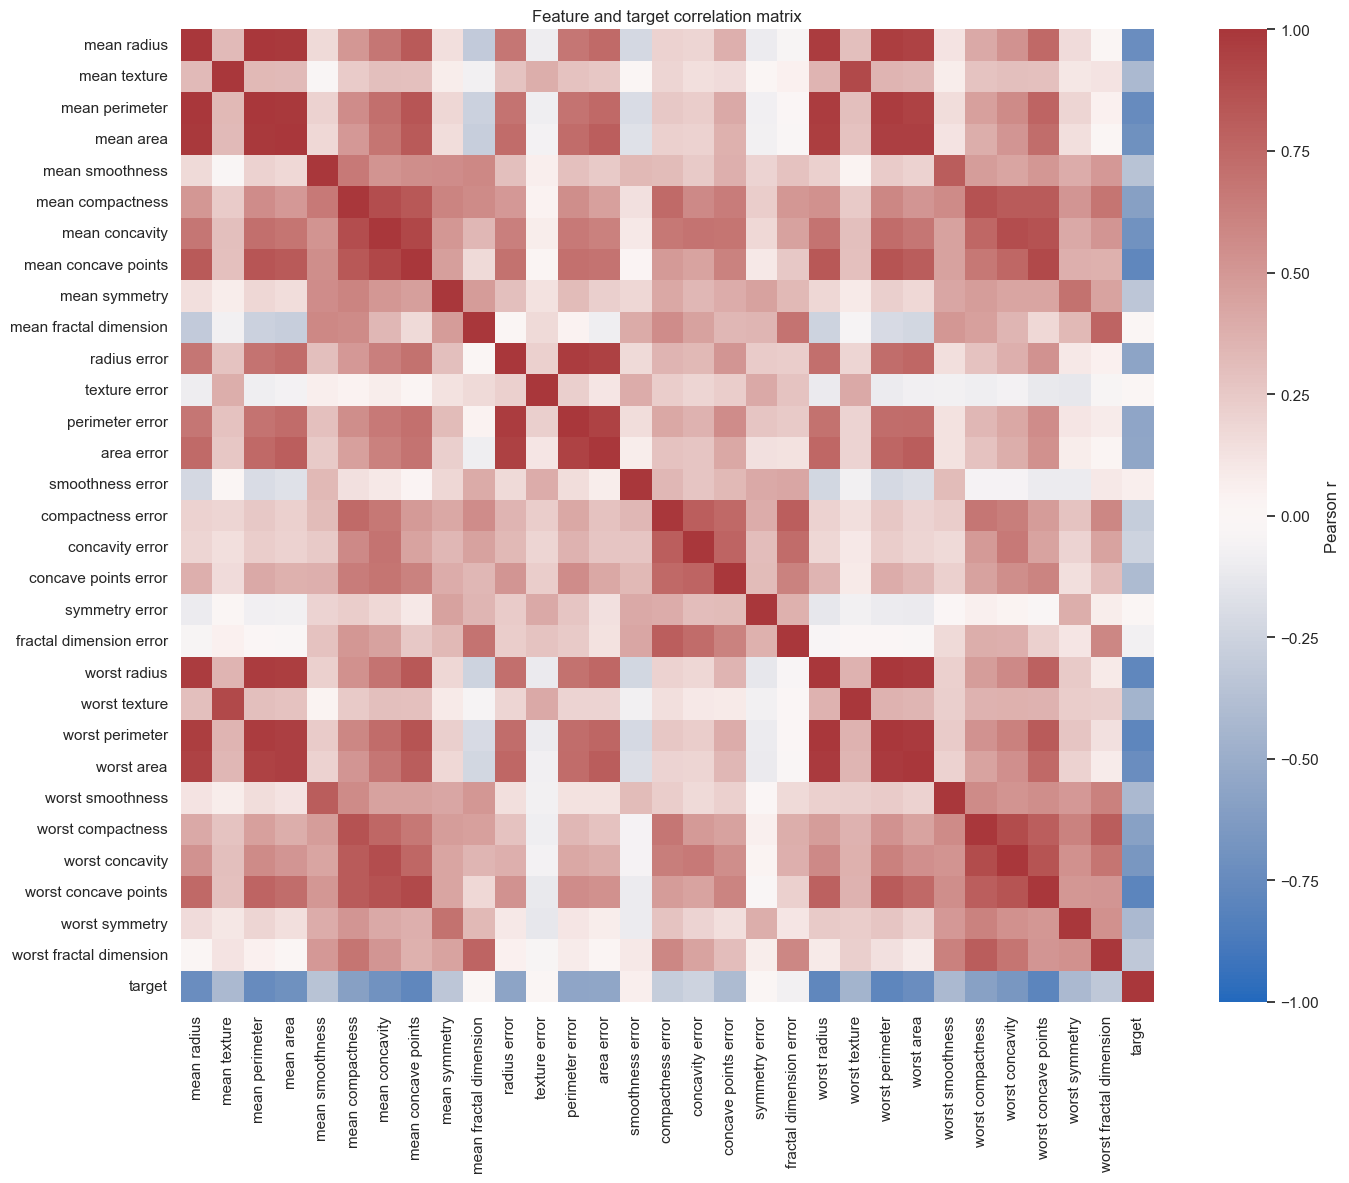

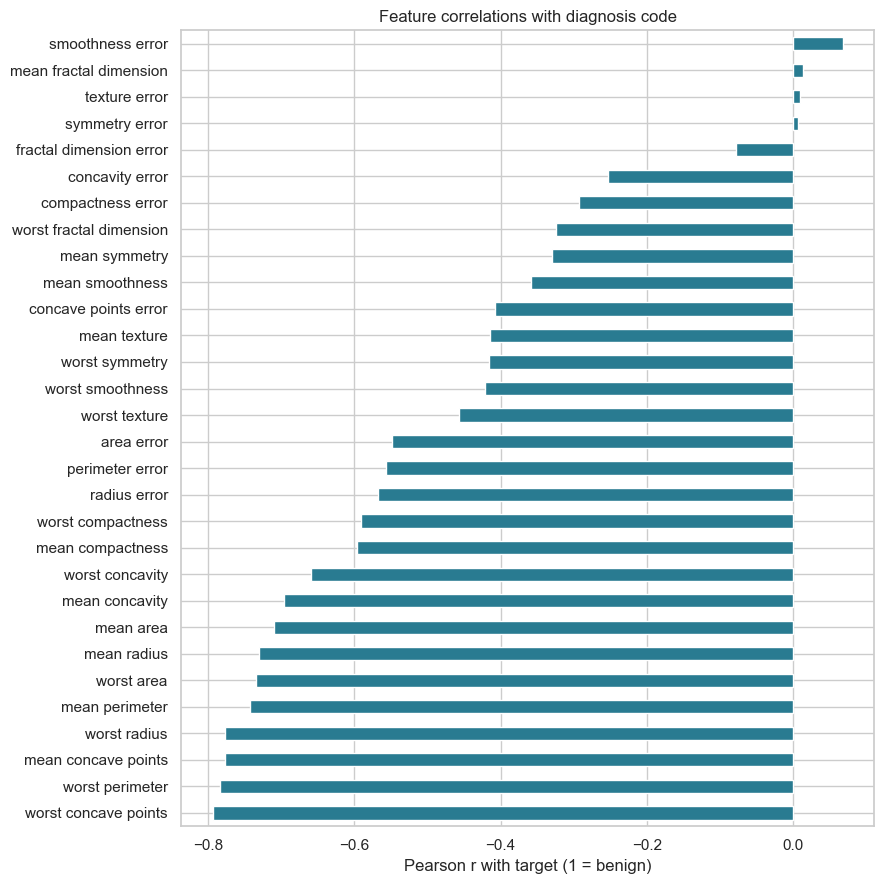

Strongest absolute correlation: worst concave points
Closest to zero: symmetry error


In [3]:
selected = ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'worst concave points']
display(eda.groupby('Diagnosis')[selected].agg(['mean','median','std']).round(3))
fig, ax = plt.subplots(figsize=(15,12))
corr = df[features + ['target']].corr()
sns.heatmap(corr, cmap='vlag', center=0, vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={'label':'Pearson r'})
ax.set_title('Feature and target correlation matrix'); plt.tight_layout(); plt.show()
target_corr = corr['target'].drop('target').sort_values()
fig, ax = plt.subplots(figsize=(9,9))
target_corr.plot.barh(ax=ax, color='#297b91'); ax.set(xlabel='Pearson r with target (1 = benign)', title='Feature correlations with diagnosis code'); plt.tight_layout(); plt.show()
print('Strongest absolute correlation:', target_corr.abs().idxmax())
print('Closest to zero:', target_corr.abs().idxmin())

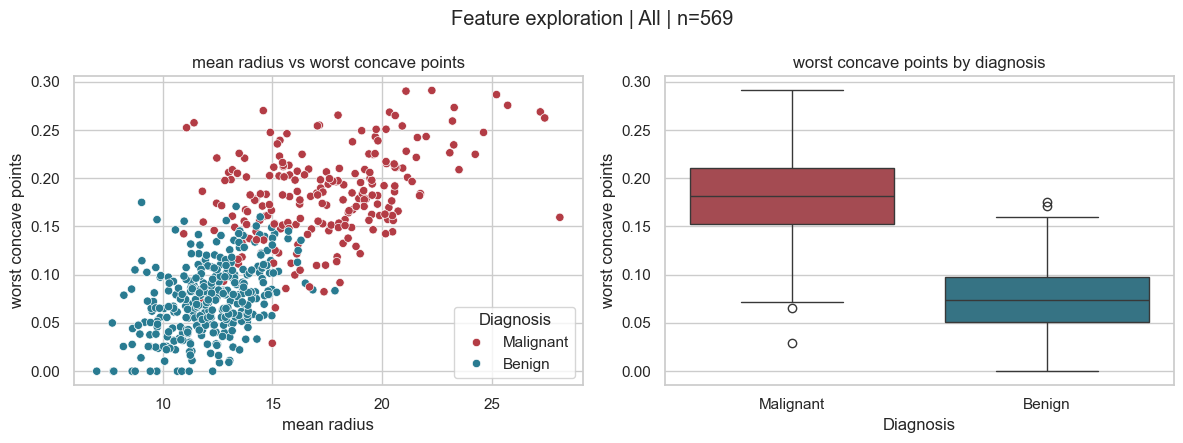

interactive(children=(Dropdown(description='x', options=('mean radius', 'mean texture', 'mean perimeter', 'mea…

In [4]:
def explore(x='mean radius', y='worst concave points', diagnosis='All'):
    subset = eda if diagnosis == 'All' else eda[eda.Diagnosis == diagnosis]
    fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
    sns.scatterplot(data=subset, x=x, y=y, hue='Diagnosis', palette=PALETTE, ax=axes[0])
    sns.boxplot(data=subset, x='Diagnosis', y=y, hue='Diagnosis', palette=PALETTE, legend=False, ax=axes[1])
    axes[0].set_title(f'{x} vs {y}'); axes[1].set_title(f'{y} by diagnosis')
    fig.suptitle(f'Feature exploration | {diagnosis} | n={len(subset)}')
    plt.tight_layout(); plt.show()
explore()
# Optional notebook dropdowns; the default plots work without ipywidgets.
try:
    import ipywidgets as widgets
except ImportError:
    print('Optional interactive controls unavailable. Install ipywidgets or call explore(x, y, diagnosis).')
else:
    display(widgets.interactive(explore,
        x=widgets.Dropdown(options=features, value='mean radius'),
        y=widgets.Dropdown(options=features, value='worst concave points'),
        diagnosis=widgets.Dropdown(options=['All'] + ORDER)))

## 4. Model training — reproducible SVM pipeline
Preserve the original linear SVM and 70/30 split with seed 42. Add stratification and a StandardScaler inside a Pipeline so scaling is fitted only on training data. Follow split → fit → score → predict. For classification, `score()` returns accuracy, not regression R².

In [5]:
X, y = df[features], df.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
assert set(X_train.index).isdisjoint(X_test.index)
model = Pipeline([('scaler', StandardScaler()), ('svc', SVC(kernel='linear'))])
model.fit(X_train, y_train)
test_accuracy = model.score(X_test, y_test)
y_pred = model.predict(X_test)
print('Training samples:', len(X_train), '| Test samples:', len(X_test))
print('Held-out accuracy:', f'{test_accuracy:.4%}')
display(pd.DataFrame({'Train': y_train.value_counts(), 'Test': y_test.value_counts()}).rename(index=LABELS))

Training samples: 398 | Test samples: 171
Held-out accuracy: 98.2456%


,Train,Test
target,,
Benign,250,107
Malignant,148,64


## 5. Held-out model evaluation
Malignant (0) is the positive class. Precision measures how many predicted malignant cases are actually malignant; recall measures the fraction of actual malignant cases detected; F1 balances precision and recall. The confusion matrix uses malignant first on both axes.

,precision,recall,f1-score,support
Malignant,0.9841,0.9688,0.9764,64.0000
Benign,0.9815,0.9907,0.9860,107.0000
accuracy,0.9825,0.9825,0.9825,0.9825
macro avg,0.9828,0.9797,0.9812,171.0000
weighted avg,0.9825,0.9825,0.9824,171.0000


,Score
Accuracy,0.9825
Precision (malignant),0.9841
Recall (malignant),0.9688
F1 (malignant),0.9764


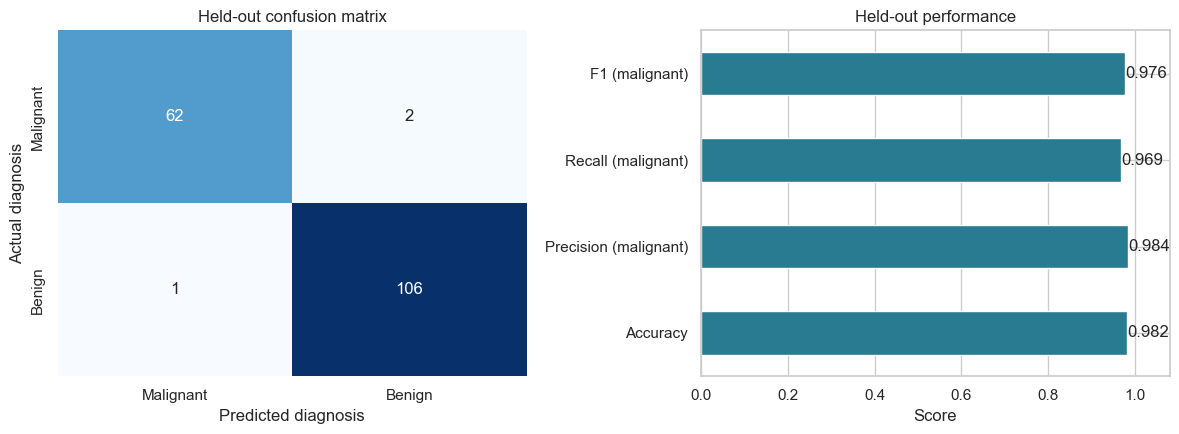

TP=62, FN=2, FP=1, TN=106 (malignant positive)
2 malignant cases predicted benign; 1 benign cases predicted malignant.


,Actual,Predicted
14,Malignant,Malignant
150,Benign,Benign
275,Benign,Benign
83,Malignant,Malignant
86,Malignant,Malignant


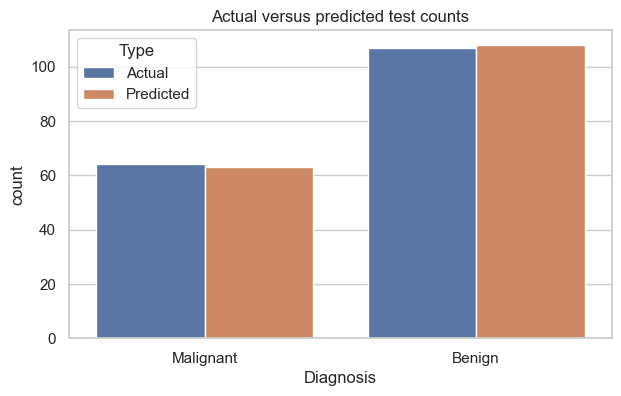

In [6]:
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
tp, fn, fp, tn = cm.ravel()
metrics = pd.Series({'Accuracy': accuracy_score(y_test, y_pred),
                     'Precision (malignant)': precision_score(y_test, y_pred, pos_label=0),
                     'Recall (malignant)': recall_score(y_test, y_pred, pos_label=0),
                     'F1 (malignant)': f1_score(y_test, y_pred, pos_label=0)})
report = pd.DataFrame(classification_report(y_test, y_pred, labels=[0,1], target_names=ORDER, output_dict=True)).T
display(report.round(4))
display(metrics.to_frame('Score').round(4))
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=ORDER, yticklabels=ORDER, ax=axes[0], cbar=False)
axes[0].set(xlabel='Predicted diagnosis', ylabel='Actual diagnosis', title='Held-out confusion matrix')
metrics.plot.barh(ax=axes[1], color='#297b91'); axes[1].set(xlim=(0,1.08), xlabel='Score', title='Held-out performance')
axes[1].bar_label(axes[1].containers[0], fmt='%.3f'); plt.tight_layout(); plt.show()
print(f'TP={tp}, FN={fn}, FP={fp}, TN={tn} (malignant positive)')
print(f'{fn} malignant cases predicted benign; {fp} benign cases predicted malignant.')
predictions = pd.DataFrame({'Actual': y_test.map(LABELS), 'Predicted': pd.Series(y_pred,index=y_test.index).map(LABELS)})
display(predictions.head())
comparison = predictions.melt(var_name='Type', value_name='Diagnosis')
fig, ax = plt.subplots(figsize=(7,4))
sns.countplot(data=comparison, x='Diagnosis', hue='Type', order=ORDER, ax=ax)
ax.set_title('Actual versus predicted test counts'); plt.show()

## 6. Verification and interpretation
Repeat the split and fit to verify that metrics and predictions are reproducible. Confirm that the training-only scaler matches training means and that the evaluation accounts for every held-out observation.

In [7]:
a,b,c,d = train_test_split(X,y,test_size=0.30,random_state=42,stratify=y)
repeat = clone(model).fit(a,c)
assert np.array_equal(b.index,X_test.index)
assert np.array_equal(repeat.predict(b),y_pred)
assert np.isclose(repeat.score(b,d),test_accuracy)
assert np.allclose(model.named_steps['scaler'].mean_, X_train.mean().to_numpy())
assert cm.sum() == len(y_test)
assert np.isclose(metrics['Accuracy'],test_accuracy)
print('PASS: reproducible split, predictions, metrics, training-only scaling and confusion matrix.')
print(f'Observed test accuracy {test_accuracy:.2%}; malignant F1 {metrics["F1 (malignant)"]:.4f}.')
print(f'Errors: {fn+fp} of {len(y_test)} test observations.')

PASS: reproducible split, predictions, metrics, training-only scaling and confusion matrix.
Observed test accuracy 98.25%; malignant F1 0.9764.
Errors: 3 of 171 test observations.


## 7. Limitations and final project deliverables
This small historical dataset does not establish clinical reliability across populations or care settings. A single held-out split is an educational estimate, not external validation. False negatives can be consequential in healthcare; false positives may lead to unnecessary follow-up. No personal patient records, clinical advice or diagnostic deployment are within scope.

This notebook supports the proposed Streamlit sections: Dataset Overview (sections 1–2), Feature Exploration (section 3), and SVM Model Evaluation (sections 4–6). The companion Streamlit application, requirements files and README are included in the final project package; Section 8 describes their use and verifies shared analysis. Live deployment is a separate step.

### Sources
- UCI Breast Cancer Wisconsin (Diagnostic): https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- scikit-learn dataset: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
- Exercise 32 Final Project Proposal (supplied document).

## 8. Streamlit Application Development and Deployment
**8.1 Setup:** Install `requirements-notebook.txt` using `python -m pip install -r requirements-notebook.txt` in a terminal.

**8.2 Architecture:** `app.py` provides three tabs, backed by `analysis_core.py` using the supplied CSV. Filters affect exploratory views only.

**8.3 Dataset Overview:** schema, quality, counts, descriptive statistics and ranges.

**8.4 Feature Exploration:** two numeric dropdowns and diagnosis filter, scatterplot, box plot, group comparisons and Pearson heatmap.

**8.5 SVM Model Evaluation:** fixed split and pipeline, held-out metrics, confusion matrix and limitations.

**8.6–8.8 Source and documentation:** `app.py`, `analysis_core.py`, `requirements.txt`, `requirements-notebook.txt`, and `README.md` are supplied alongside this notebook. The next cell verifies their presence and checks metric parity.

In [8]:
from analysis_core import load_data, evaluate, filter_data
for filename in ['app.py','analysis_core.py','requirements.txt','README.md']:
    assert Path(filename).is_file(), filename
app_df = load_data()
app_metrics, app_cm, app_report, app_train, app_test, app_pred = evaluate(app_df)
assert np.allclose(list(app_metrics.values()), metrics.to_numpy())
assert np.array_equal(app_cm, cm)
assert np.array_equal(app_pred, y_pred)
assert (app_train, app_test) == (len(X_train),len(X_test))
for label, expected in [('All',569),('Malignant',212),('Benign',357)]:
    assert len(filter_data(app_df,label)) == expected
print('PASS: application analysis matches notebook metrics, predictions and confusion matrix; filter counts verified.')

PASS: application analysis matches notebook metrics, predictions and confusion matrix; filter counts verified.


**8.9 Local execution and verification:** From the extracted folder, run `python -m streamlit run app.py` in a terminal. Run `python -m unittest -v test_project` to exercise core logic and, when installed, Streamlit AppTest. Inspect all tab charts, labels and controls in a browser. Streamlit runtime verification was blocked in the packaging environment by missing Streamlit and unavailable package network access; see VERIFICATION.txt.

**8.10 Deployment:** Push the source files to GitHub, deploy app.py through Streamlit Community Cloud, check the URL and submit the required files/link to Canvas. See README.md. No public deployment or Canvas submission has been performed.